## Переход к полной подразумеваемой дисперсии

Для применения формулы Дюпира переходим от *implied volatility* к полной подразумеваемой дисперсии $w(T,k)=T\sigma_{\mathrm{impl}}^2(T,k)$, где $k=\log\frac{K}{F(T)}$ - *forward log-moneyness*.

Использование координаты $k$ позволяет записать формулу Дюпира через поверхность $w(T,k)$ и её производные. При этом производная $w_T$ вычисляется при фиксированном $k$, то есть при фиксированном отношении $\frac{K}{F(T)}$, а не при фиксированном страйке $K$.

При достаточно гладкой поверхности $w(T,k)$ локальная дисперсия определяется формулой $\sigma_{\mathrm{loc}}^2(T,k)=\frac{w_T(T,k)}{g(T,k)}$, где $g(T,k)=\left(1-\frac{kw_k}{2w}\right)^2-\frac{1}{4}\left(\frac{1}{w}+\frac{1}{4}\right)w_k^2+\frac{1}{2}w_{kk}$.

Здесь $w_T=\frac{\partial w}{\partial T}$, $w_k=\frac{\partial w}{\partial k}$ и $w_{kk}=\frac{\partial^2w}{\partial k^2}$.

Для корректного вычисления *local volatility* требуется выполнение условий $w(T,k)>0$, $w_T(T,k)\geq0$ и $g(T,k)>0$.

Условие $w_T(T,k)\geq0$ соответствует отсутствию *calendar-arbitrage*, а условие $g(T,k)\geq0$ соответствует отсутствию *butterfly-arbitrage*. Для деления в формуле Дюпира требуется более строгое условие $g(T,k)>0$.

Формула используется в координатах, связанных с форвардом, и предполагает детерминированные кривые процентных ставок и дивидендов, которые уже учтены в $F(T)$ и $D(T)$.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go

from pathlib import Path
from scipy.interpolate import RectBivariateSpline

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / 'data'
PROCESSED_DIR = DATA_DIR / 'processed'

from src.black import implied_vol, normalized_call_from_total_variance
from src.arbitrage import surface_arbitrage_report
from src.plotting import dark_3d_surface, apply_dark_3d_style

In [2]:
rational_price_nodes = pd.read_parquet(PROCESSED_DIR / 'rational_price_nodes.parquet')
rational_price_nodes = rational_price_nodes.sort_values(['T', 'log_moneyness']).reset_index(drop=True)

T_nodes = np.sort(rational_price_nodes['T'].unique())
log_moneyness_grid = np.sort(rational_price_nodes['log_moneyness'].unique())
moneyness_grid = np.exp(log_moneyness_grid)

expected_size = len(T_nodes) * len(log_moneyness_grid)

if rational_price_nodes.duplicated(['T', 'log_moneyness']).any():
    raise ValueError('В таблице присутствуют повторяющиеся пары (T, log_moneyness)')

if len(rational_price_nodes) != expected_size:
    raise ValueError('Таблица узловых цен не образует полную прямоугольную сетку')

normalized_call_nodes = rational_price_nodes['normalized_call_price'].to_numpy().reshape(
    len(T_nodes),
    len(log_moneyness_grid)
)

print('Количество исходных сроков:', len(T_nodes))
print('Количество значений log-moneyness:', len(log_moneyness_grid))
print('Размер матрицы нормированных цен:', normalized_call_nodes.shape)

Количество исходных сроков: 35
Количество значений log-moneyness: 1000
Размер матрицы нормированных цен: (35, 1000)


### Восстановление узловой implied volatility

Для построения поверхности $w(T,k)$ используем только исходные сроки $T_i$ и нормированные call-цены $c(T_i,x_j)$. Линейно интерполированные по времени цены на этом этапе не используются.

Для устойчивого обращения формулы Блека переходим от нормированной call-цены к цене OTM-опциона. При $x_j\geq1$ используем call-цену $q(T_i,x_j)=c(T_i,x_j)$, а при $x_j<1$ используем put-цену $q(T_i,x_j)=c(T_i,x_j)-(1-x_j)$.

В нормированных координатах можно положить $F=1$, $D=1$ и $K=x_j$. Это не означает, что реальные форвард и коэффициент дисконтирования равны единице: они уже были учтены при нормировании исходной call-цены.

По каждой OTM-цене обращаем формулу Блека, получаем $\sigma_{\mathrm{impl}}(T_i,k_j)$ и вычисляем узловую полную дисперсию $w_{ij}=T_i\sigma_{\mathrm{impl}}^2(T_i,k_j)$.

Перед построением сплайна проверяем, что все значения $w_{ij}$ конечны и положительны.

In [3]:
T_node_mesh, x_node_mesh = np.meshgrid(
    T_nodes,
    moneyness_grid,
    indexing='ij'
)

node_option_prices = np.where(
    x_node_mesh >= 1,
    normalized_call_nodes,
    normalized_call_nodes - (1 - x_node_mesh)
)

node_impl_vol = implied_vol(
    np.ones_like(x_node_mesh),
    T_node_mesh,
    x_node_mesh,
    node_option_prices,
    x_node_mesh >= 1,
    np.ones_like(x_node_mesh)
)

total_variance_nodes = T_node_mesh * (node_impl_vol)**2

non_finite_nodes = np.sum(~np.isfinite(total_variance_nodes))

print('Размер матрицы total variance:', total_variance_nodes.shape)
print('Количество non-finite значений:', non_finite_nodes)
print('Минимальное значение total variance:', np.nanmin(total_variance_nodes))

if non_finite_nodes > 0:
    raise ValueError('В узловой total variance присутствуют non-finite значения')

Размер матрицы total variance: (35, 1000)
Количество non-finite значений: 0
Минимальное значение total variance: 0.0002291180656466856


### Сглаживание поверхности полной подразумеваемой дисперсии

Рациональный сплайн call-цен строился отдельно для каждого срока и является только $C^1$-гладким. Его вторая производная может скачкообразно изменяться в исходных узлах, поэтому непосредственное дифференцирование этого сплайна в формуле Дюпира приводит к нестабильной *local volatility*.

Вместо этого по узловым значениям $w_{ij}=w(T_i,k_j)$ строим гладкую поверхность $\widehat{w}(T,k)$ с помощью `RectBivariateSpline`.

Используем бикубический B-сплайн степени 3 по времени $T$ и степени 3 по *log-moneyness* $k$. В общем виде поверхность записывается как $\widehat{w}(T,k)=\sum_p\sum_q c_{pq}B_{p,3}(T)B_{q,3}(k)$, где $c_{pq}$ — коэффициенты сплайна, а $B_{p,3}$ и $B_{q,3}$ — кубические базисные B-сплайны.

Параметр сглаживания задаём как $s=10^{-4}\sum_{i,j}w_{ij}^2$. Сплайн подбирается так, чтобы выполнялось условие $\sum_{i,j}\left(\widehat{w}(T_i,k_j)-w_{ij}\right)^2\leq s$.

Слишком маленькое сглаживание может сохранить шум и сделать производные нестабильными, а слишком большое может заметно исказить исходные улыбки.

Качество сглаживания оцениваем по ошибкам в исходных узлах, устойчивости производных, отсутствию арбитражных нарушений.

Построенная поверхность позволяет аналитически вычислять производные $\widehat{w}_T(T,k)$, $\widehat{w}_k(T,k)$ и $\widehat{w}_{kk}(T,k)$.

`RectBivariateSpline` сам по себе не гарантирует выполнение условий $\widehat{w}>0$, $\widehat{w}_T\geq0$ и $g(T,k)\geq0$. Поэтому после сглаживания все условия необходимо повторно проверить на плотной сетке.

In [4]:
relative_smoothing = 1e-4
smoothing = relative_smoothing * np.sum(total_variance_nodes**2)

total_variance_spline = RectBivariateSpline(T_nodes, log_moneyness_grid, total_variance_nodes, kx=3, ky=3, s=smoothing)

fitted_total_variance_nodes = total_variance_spline(T_nodes, log_moneyness_grid)
skeleton_error = np.abs(fitted_total_variance_nodes - total_variance_nodes)
relative_skeleton_error = skeleton_error / np.maximum(total_variance_nodes, 1e-12)

print('Максимальная ошибка на исходных узлах:', skeleton_error.max())
print('Средняя ошибка на исходных узлах:', skeleton_error.mean())
print('Максимальная относительная ошибка на исходных узлах:', relative_skeleton_error.max())
print('Медианная относительная ошибка на исходных узлах:', np.median(relative_skeleton_error))

T_dupire_grid = np.linspace(T_nodes.min(), T_nodes.max(), 500)
k_dupire_grid = log_moneyness_grid.copy()
T_dupire_mesh, k_dupire_mesh = np.meshgrid(T_dupire_grid, k_dupire_grid, indexing='ij')

w = total_variance_spline(T_dupire_grid, k_dupire_grid)
w_T = total_variance_spline(T_dupire_grid, k_dupire_grid, dx=1, dy=0)
w_k = total_variance_spline(T_dupire_grid, k_dupire_grid, dx=0, dy=1)
w_kk = total_variance_spline(T_dupire_grid, k_dupire_grid, dx=0, dy=2)

dupire_denominator = (1 - k_dupire_mesh * w_k / (2 * w))**2 - 0.25 * (1 / w + 0.25) * w_k**2 + 0.5 * w_kk

Максимальная ошибка на исходных узлах: 0.0006296398781095482
Средняя ошибка на исходных узлах: 8.582875421518268e-05
Максимальная относительная ошибка на исходных узлах: 0.13595236690499374
Медианная относительная ошибка на исходных узлах: 0.013221082518772962


### Диагностика сглаженной поверхности полной дисперсии

На плотной сетке по $T$ и $k$ вычисляем значения $\widehat{w}$ и производные $\widehat{w}_T$, $\widehat{w}_k$, $\widehat{w}_{kk}$.

После этого вычисляем знаменатель формулы Дюпира $g(T,k)=\left(1-\frac{k\widehat{w}_k}{2\widehat{w}}\right)^2-\frac{1}{4}\left(\frac{1}{\widehat{w}}+\frac{1}{4}\right)\widehat{w}_k^2+\frac{1}{2}\widehat{w}_{kk}$.

Проверяем следующие условия:

1) Значения $\widehat{w}$, $\widehat{w}_T$, $\widehat{w}_k$, $\widehat{w}_{kk}$ и $g(T,k)$ должны быть конечными.

2) Полная подразумеваемая дисперсия должна быть положительной: $\widehat{w}(T,k)>0$.

3) Для отсутствия *calendar-arbitrage* требуется $\widehat{w}_T(T,k)\geq0$.

4) Для отсутствия *butterfly-arbitrage* требуется $g(T,k)\geq0$.

5) Для вычисления конечной локальной дисперсии требуется строгое условие $g(T,k)>0$.

В точках, где все условия выполнены, вычисляем локальную дисперсию как $\sigma_{\mathrm{loc}}^2(T,k)=\frac{\widehat{w}_T(T,k)}{g(T,k)}$, после чего получаем локальную волатильность $\sigma_{\mathrm{loc}}(T,k)=\sqrt{\sigma_{\mathrm{loc}}^2(T,k)}$.

Нарушения проверяются только на выбранной конечной сетке. Отсутствие нарушений на этой сетке является численной диагностикой, но не строгим доказательством отсутствия арбитража во всей непрерывной области.

In [5]:
finite_mask = np.isfinite(w) & np.isfinite(w_T) & np.isfinite(w_k) & np.isfinite(w_kk) & np.isfinite(dupire_denominator)
positive_variance_mask = w > 0
calendar_mask = w_T >= 0
butterfly_mask = dupire_denominator > 0
valid_mask = finite_mask & positive_variance_mask & calendar_mask & butterfly_mask

local_variance_mesh = np.full_like(w, np.nan)
local_variance_mesh[valid_mask] = w_T[valid_mask] / dupire_denominator[valid_mask]
local_vol_mesh = np.sqrt(local_variance_mesh)

print('Количество non-finite точек:', finite_mask.size - finite_mask.sum())
print('Количество точек с неположительной total variance:', np.sum(finite_mask & ~positive_variance_mask))
print('Количество нарушений calendar arbitrage:', np.sum(finite_mask & ~calendar_mask))
print('Количество нарушений butterfly arbitrage:', np.sum(finite_mask & ~butterfly_mask))
print('Минимальное значение w_T:', np.min(w_T[finite_mask]))
print('Минимальное значение Dupire denominator:', np.min(dupire_denominator[finite_mask]))
print('Количество допустимых точек local volatility:', valid_mask.sum())
print('Доля допустимых точек:', valid_mask.mean())

local_vol_surface = pd.DataFrame({
    'T': T_dupire_mesh.ravel(),
    'log_moneyness': k_dupire_mesh.ravel(),
    'moneyness': np.exp(k_dupire_mesh).ravel(),
    'total_variance': w.ravel(),
    'w_T': w_T.ravel(),
    'w_k': w_k.ravel(),
    'w_kk': w_kk.ravel(),
    'dupire_denominator': dupire_denominator.ravel(),
    'local_variance': local_variance_mesh.ravel(),
    'local_vol': local_vol_mesh.ravel(),
    'valid': valid_mask.ravel()
})

local_vol_surface

Количество non-finite точек: 0
Количество точек с неположительной total variance: 0
Количество нарушений calendar arbitrage: 0
Количество нарушений butterfly arbitrage: 0
Минимальное значение w_T: 0.010903186733524478
Минимальное значение Dupire denominator: 0.04028449516163598
Количество допустимых точек local volatility: 500000
Доля допустимых точек: 1.0


,T,log_moneyness,moneyness,total_variance,w_T,w_k,w_kk,dupire_denominator,local_variance,local_vol,valid
0,0.019178,-0.215781,0.805912,0.006700,0.074170,-0.048534,0.161253,0.040284,1.841143,1.356887,True
1,0.019178,-0.215529,0.806115,0.006687,0.074087,-0.048494,0.161314,0.040364,1.835498,1.354805,True
2,0.019178,-0.215277,0.806318,0.006675,0.074005,-0.048453,0.161375,0.040443,1.829865,1.352725,True
3,0.019178,-0.215025,0.806521,0.006663,0.073923,-0.048413,0.161437,0.040522,1.824244,1.350646,True
4,0.019178,-0.214773,0.806725,0.006651,0.073841,-0.048372,0.161498,0.040602,1.818635,1.348568,True
...,...,...,...,...,...,...,...,...,...,...,...
499995,0.904110,0.034973,1.035592,0.020524,0.028382,-0.092159,0.328874,1.223658,0.023195,0.152297,True
499996,0.904110,0.035225,1.035853,0.020501,0.028357,-0.092076,0.329197,1.225150,0.023146,0.152139,True
499997,0.904110,0.035477,1.036114,0.020478,0.028333,-0.091993,0.329519,1.226643,0.023098,0.151980,True
499998,0.904110,0.035729,1.036375,0.020454,0.028308,-0.091910,0.329842,1.228137,0.023050,0.151821,True


### Повторная проверка сглаженной поверхности в пространстве цен

Ранее условия отсутствия арбитража проверялись для линейно интерполированной поверхности нормированных call-цен. Однако для вычисления *local volatility* была построена новая сглаженная поверхность $\widehat{w}(T,k)$.

Поэтому из $\widehat{w}(T,k)$ повторно восстанавливаем нормированные call-цены по формуле Блека и проверяем их границы, монотонность, выпуклость и неубывание по времени.

Для каждой точки определяем $d_1=-\frac{k}{\sqrt{\widehat{w}}}+\frac{\sqrt{\widehat{w}}}{2}$ и $d_2=d_1-\sqrt{\widehat{w}}$. Тогда нормированная call-цена равна $c(T,k)=N(d_1)-e^kN(d_2)$.

In [6]:
smoothed_normalized_calls = normalized_call_from_total_variance(
    k_dupire_mesh,
    w
)

surface_arbitrage_report(smoothed_normalized_calls, moneyness_grid)

Нарушения нижней границы цены: 0
Нарушения верхней границы цены: 0
Нарушения calendar arbitrage: 0
Нарушения верхней границы наклона: 0
Нарушения нижней границы наклона: 0
Нарушения butterfly arbitrage: 0
Диапазон наклона: -0.9993502844550972 -0.010074848856920095


{'lower_price_violations': 0,
 'upper_price_violations': 0,
 'calendar_violations': 0,
 'upper_slope_violations': 0,
 'lower_slope_violations': 0,
 'butterfly_violations': 0,
 'minimum_slope': -0.9993502844550972,
 'maximum_slope': -0.010074848856920095}

## Визуализация local volatility

По времени исключаем первый и последний исходные сроки, а по *log-moneyness* исключаем по 10 крайних точек сетки.

Такое ограничение используется, потому что производные сглаживающего сплайна обычно менее устойчивы около границ области. Особенно чувствительны вторая производная $\widehat{w}_{kk}$ и знаменатель формулы Дюпира $g(T,k)$.

В точках, где не выполнено хотя бы одно из условий $\widehat{w}>0$, $\widehat{w}_T\geq0$ или $g(T,k)>0$, значение *local volatility* заменяется на `NaN` и не отображается на графике.

In [7]:
time_mask = (T_dupire_grid >= T_nodes[1]) & (T_dupire_grid <= T_nodes[-2])
k_slice = slice(10, -10)

T_plot_mesh = T_dupire_mesh[time_mask, k_slice]
k_plot_mesh = k_dupire_mesh[time_mask, k_slice]
local_vol_for_plot = np.where(valid_mask, local_vol_mesh, np.nan)[time_mask, k_slice]

time_step = max(1, T_plot_mesh.shape[0] // 250)
k_step = max(1, T_plot_mesh.shape[1] // 160)

fig = dark_3d_surface(
    x=k_plot_mesh[::time_step, ::k_step],
    y=T_plot_mesh[::time_step, ::k_step],
    z=local_vol_for_plot[::time_step, ::k_step] * 100,
    title='Local volatility: внутренняя область',
    zaxis_title='Local volatility, %',
    name='Local volatility',
    colorscale='Plasma'
)

fig.show(config={'displaylogo': False, 'responsive': True})

### Сравнение implied volatility и local volatility

Из сглаженной полной дисперсии восстанавливаем *implied volatility* по формуле $\sigma_{\mathrm{impl}}(T,k)=\sqrt{\frac{\widehat{w}(T,k)}{T}}$.

На одном графике отображаем $\sigma_{\mathrm{impl}}(T,k)$ и $\sigma_{\mathrm{loc}}(T,k)$.

In [8]:
implied_vol_mesh = np.sqrt(w / T_dupire_mesh)
implied_vol_for_plot = implied_vol_mesh[time_mask, k_slice]
local_vol_for_plot = np.where(valid_mask, local_vol_mesh, np.nan)[time_mask, k_slice]

time_step = max(1, T_plot_mesh.shape[0] // 250)
k_step = max(1, T_plot_mesh.shape[1] // 160)
mesh_slice = (slice(None, None, time_step), slice(None, None, k_step))

fig = go.Figure()

fig.add_trace(go.Surface(
    x=k_plot_mesh[mesh_slice],
    y=T_plot_mesh[mesh_slice],
    z=implied_vol_for_plot[mesh_slice] * 100,
    colorscale=[[0, '#4c78ff'], [1, '#4c78ff']],
    opacity=0.5,
    showscale=False,
    showlegend=True,
    name='Implied volatility',
    lighting=dict(ambient=0.75, diffuse=0.8, roughness=0.9),
    hovertemplate='k: %{x:.3f}<br>T: %{y:.3f}<br>IV: %{z:.2f}%<extra></extra>'
))

fig.add_trace(go.Surface(
    x=k_plot_mesh[mesh_slice],
    y=T_plot_mesh[mesh_slice],
    z=local_vol_for_plot[mesh_slice] * 100,
    colorscale=[[0, '#ff8c42'], [1, '#ff8c42']],
    opacity=0.55,
    showscale=False,
    showlegend=True,
    name='Local volatility',
    lighting=dict(ambient=0.75, diffuse=0.8, roughness=0.9),
    hovertemplate='k: %{x:.3f}<br>T: %{y:.3f}<br>LV: %{z:.2f}%<extra></extra>'
))

apply_dark_3d_style(
    fig,
    title='Implied volatility vs Local volatility',
    zaxis_title='Volatility, %'
)

fig.show(config={'displaylogo': False, 'responsive': True})

### Сравнение срезов при разных экспирациях

Для более подробного сравнения рассматриваем два среза поверхностей при сроках, ближайших к 30 и 180 дням.

Для каждого срока на одном графике отображаем зависимости $\sigma_{\mathrm{impl}}(T,k)$ и $\sigma_{\mathrm{loc}}(T,k)$ от *log-moneyness* $k$.

Если точного значения $T$ нет среди исходных экспираций, выбирается ближайший доступный срок $T_i$. Поэтому фактическая экспирация выводится в заголовке каждого графика.

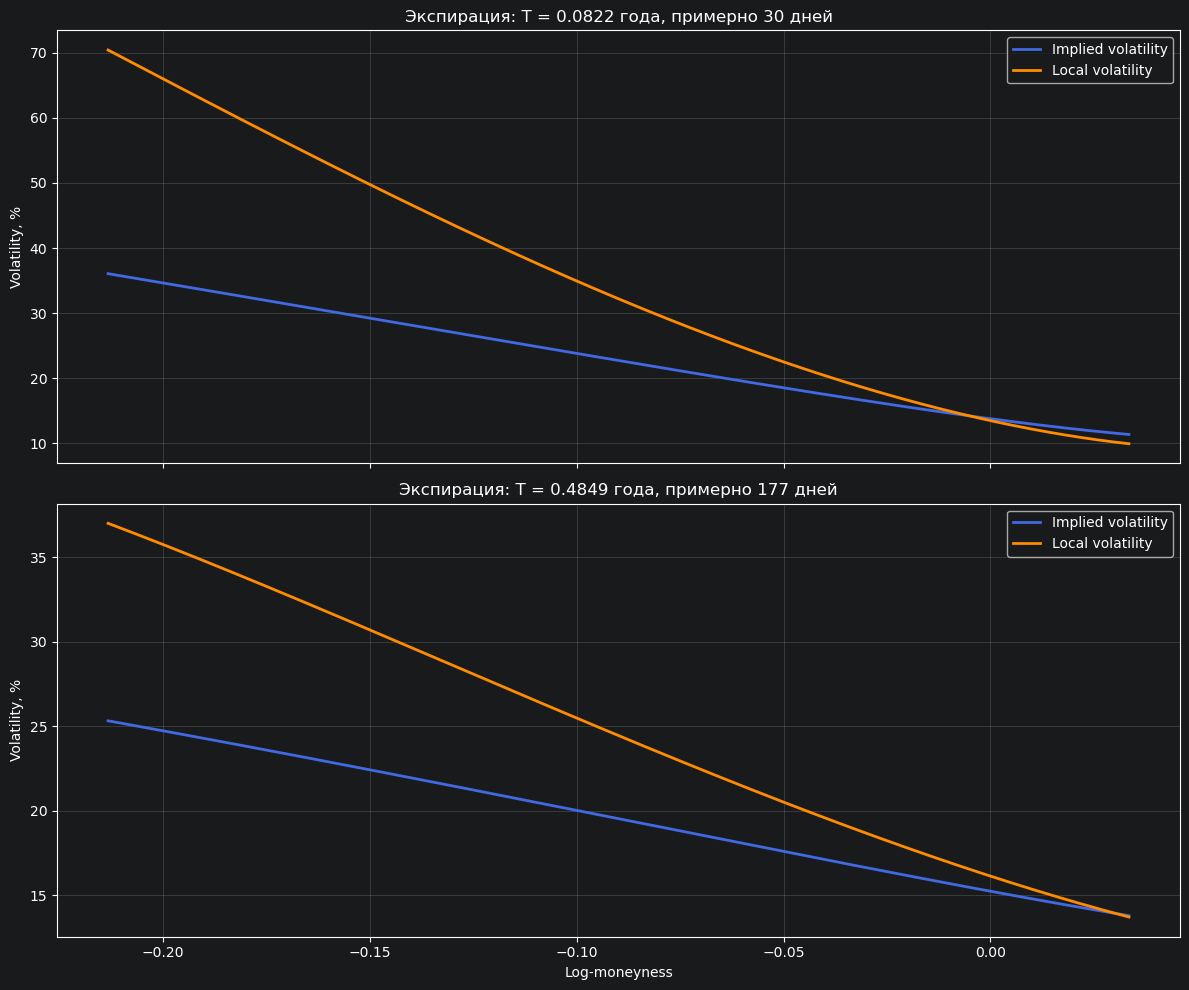

In [9]:
target_expirations = [30 / 365, 180 / 365]
selected_expirations = [T_nodes[np.argmin(np.abs(T_nodes - target_T))] for target_T in target_expirations]
selected_rows = [np.argmin(np.abs(T_dupire_grid - T)) for T in selected_expirations]

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for ax, row, T in zip(axes, selected_rows, selected_expirations):
    ax.plot(
        k_dupire_grid[k_slice],
        implied_vol_mesh[row, k_slice] * 100,
        color='royalblue',
        linewidth=2,
        label='Implied volatility'
    )

    ax.plot(
        k_dupire_grid[k_slice],
        local_vol_mesh[row, k_slice] * 100,
        color='darkorange',
        linewidth=2,
        label='Local volatility'
    )

    ax.set_ylabel('Volatility, %')
    ax.set_title(f'Экспирация: T = {T:.4f} года, примерно {T * 365:.0f} дней')
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel('Log-moneyness')

plt.tight_layout()
plt.show()

In [10]:
local_vol_surface['implied_vol'] = np.sqrt(local_vol_surface['total_variance'] / local_vol_surface['T'])

local_vol_surface.to_parquet(PROCESSED_DIR / 'dupire_surface.parquet', index=False)

print('Сохранено строк:', len(local_vol_surface))
print('Количество сроков:', local_vol_surface['T'].nunique())
print('Количество значений log-moneyness:', local_vol_surface['log_moneyness'].nunique())

Сохранено строк: 500000
Количество сроков: 500
Количество значений log-moneyness: 1000
